In [ ]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
from training.train import train_torch, sample_numpyro
import matplotlib.pyplot as plt
from training.evaluate import (
    evaluate_model,
    evaluate_numpyro,
    evaluate_numpyro_on_train_set,
)
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_combined,
    plot_bnn_gamma_combined,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd
from types import SimpleNamespace

In [19]:
# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# file_name = "WindPowerQuantile_2025-12-21_10-21-23_forecast_gen_ELSPOT_NO1"

model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3"

# model_cfg = load_config("../configs/model/torch_model_quantile_NO3.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_weighted_2026-02-16_21-27-08_nowcast_gen_ELSPOT_NO3"

In [ ]:
data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [21]:
data = load_dataset(data_cfg)

Loading forecast data for ELSPOT NO3, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO3 and nowcast
  Saved at: 2026-02-23 11:17:56
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)
All parks operational from 2022-10-12 12:00:00
Before 2-day ahead filtering: 1316376 rows
After 2-day ahead filtering: 489192 rows
Lead time range: 34.0h to 61.0h
                          windpark                  time_ref  lead_time_hours  \
time                                                                            
2022-10-12 12:00:00+02:00    Smøla 2022-10-10 14:00:00+02:00               46   
2022-10-12 13:00:00+02:00    Smøla 2022-10-10 14:00:00+02:00               47   
2022-10-12 14:00:00+02:00    Smøla 2022-10-10 14:00:00+02:00               4

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (18069, 24, 15, 10)
Preprocessing done. X_test shape: (1895, 24, 15, 10)


In [22]:
if data_cfg.dataset == "nowcast":
    save_scaler_params(
        scaler_params=data["scaler_params"],
        site_scaler_params=data["site_scaler_params"],
        bid_zone=data_cfg.bid_zone,
        split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
        dataset=data_cfg.dataset,
        dir_path="../checkpoints",
    )

In [24]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_outline,
    plot_qr_hdi_prediction_ensemble_std,
    plot_qr_hdi_prediction_ensemble_std_bands,
    plot_bnn_gamma_combined,
)

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3.pkl


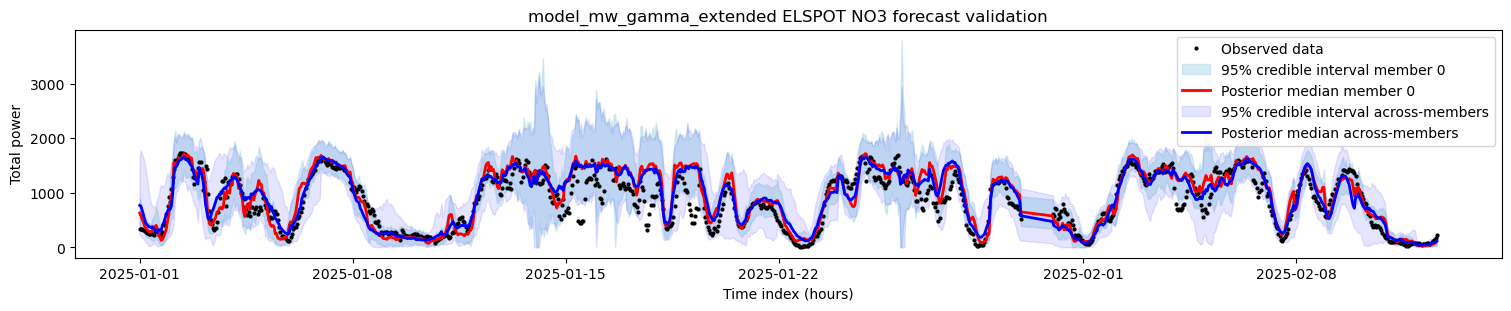

In [25]:
checkpoint = load_checkpoint(file_name=file_name)
model = build_model(checkpoint["model_cfg"], data)

plot_bnn_gamma_combined(
    checkpoint,
    model,
    data,
    data_cfg,
    1000,
)
plt.show()

In [26]:
median_list = []
hdi_list = []
percentile_list = []
y_pred_list = []

for member in range(15):

    if model_cfg.backend == "torch":
        # Quantiles
        if model_cfg.params.quantiles is None:
            quantiles = torch.linspace(0, 1, 51)
        else:
            quantiles = torch.tensor(model_cfg.params.quantiles)
        model, checkpoint = load_torch_model(file_name=file_name, quantiles=quantiles)

        metrics, y_pred = evaluate_model(
            model=model,
            data=data,
            quantiles=quantiles,
            model_cfg=checkpoint["model_cfg"],
            data_cfg=data_cfg,
            member=member,
        )

        hdis, _, _, _ = approximate_qr_intervals(
            Y_pred=y_pred,
            taus=quantiles,
            cred_mass=0.95,
        )

        # Extract curves, TODO: not 95% CI!!
        median, lower, upper = extract_quantile_curves(
            Y_pred_quantiles=y_pred,
            quantiles=quantiles,
            median_q=0.5,
            lower_q=0.02,
            upper_q=0.98,
        )

        percentiles = np.stack([lower, upper], axis=1)

        median_list.append(median)
        hdi_list.append(hdis.T)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    elif model_cfg.backend == "numpyro":

        checkpoint = load_checkpoint(file_name=file_name)
        model = build_model(checkpoint["model_cfg"], data)
        samples = checkpoint["samples"]
        metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
            model=model,
            samples=checkpoint["samples"],
            rng_key_predict=checkpoint["rng_key_predict"],
            data=data,
            model_cfg=checkpoint["model_cfg"],
            member=member,
        )
        if member == 0:
            print(metrics)

        median_list.append(median)
        hdi_list.append(hdis)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    # print(metrics)

    if data_cfg.dataset == "nowcast":
        # validate on nowcast, only one loop, otherwise validation on all ensemble members
        print("break")
        break


# assert checkpoint["model_cfg"] == model_cfg

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3.pkl
RMSE train: 250.61267
CRPS train:  132.00886061500069
RMSE val: 257.4213
CRPS val:  140.3034714139484 

{'rmse_median': np.float32(257.4213), 'coverage_025_975': np.float64(0.7693931398416887), 'coverage_0_50': np.float64(0.6147757255936676), 'crps': np.float64(140.3034714139484)}
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3.pkl
RMSE train: 297.55902
CRPS train:  163.3239424546527
RMSE val: 295.39996
CRPS val:  166.25860431794683 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3.pkl
RMSE train: 289.02927
CRPS train:  157.1899007835817
RMSE val: 299.241
CRPS val:  169.5625276265624 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3.pkl
RMSE train: 292.88177
CRPS train:  160.2991838719045
RMSE val: 

In [29]:
median_df = pd.DataFrame(
    np.column_stack(median_list),
    columns=[f"median_{i}" for i in range(len(median_list))],
)

hdi_dict = {}

for i, arr in enumerate(hdi_list):
    hdi_dict[f"hdi_lower_{i}"] = arr[0]
    hdi_dict[f"hdi_upper_{i}"] = arr[1]

hdi_df = pd.DataFrame(hdi_dict)

ensemble_results = pd.concat([median_df, hdi_df], axis=1)

median_cols = ensemble_results.filter(regex=r"^median_").columns
hdi_lower_cols = ensemble_results.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = ensemble_results.filter(regex=r"^hdi_upper_").columns

ensemble_results["mean_median"] = ensemble_results[median_cols].mean(axis=1)
ensemble_results["std_median"] = ensemble_results[median_cols].std(axis=1)
ensemble_results["mean_hdi_lower"] = ensemble_results[hdi_lower_cols].mean(axis=1)
ensemble_results["std_hdi_lower"] = ensemble_results[hdi_lower_cols].std(axis=1)
ensemble_results["mean_hdi_upper"] = ensemble_results[hdi_upper_cols].mean(axis=1)
ensemble_results["std_hdi_upper"] = ensemble_results[hdi_upper_cols].std(axis=1)

In [31]:
# import numpy as np

# for k, v in samples.items():
#     v = np.asarray(v)
#     print(
#         f"{k:20s} shape={v.shape} finite={np.isfinite(v).all()} "
#         f"min={np.nanmin(v):.3g} max={np.nanmax(v):.3g}"
#     )

In [32]:
# import numpy as np
# import arviz as az

# posterior = {k: np.asarray(v)[None, ...] for k, v in samples.items()}  # (1, 100, ...)

# idata = az.from_dict(posterior=posterior)
# az.plot_trace(idata, var_names=["b1", "b2", "b3mu", "b3k"])

In [33]:
# import matplotlib.pyplot as plt

# i = 0
# plt.plot(samples["mu"][:, i])
# plt.title(f"Trace mu[{i}]")
# plt.show()

### Plots


In [34]:
if model_cfg.backend == "numpyro":
    X_test = data["X_test"]
    if len(X_test.shape) == 4:
        X_test = X_test[:, :, 0]
    graph = numpyro.render_model(
        model,
        model_args=(X_test,),
    )
    graph

In [35]:
try:
    graph
except:
    pass

In [36]:
checkpoint.keys()

dict_keys(['samples', 'rng_key', 'rng_key_predict', 'model_cfg'])

In [ ]:
if model_cfg.backend == "numpyro":
    (
        metrics_train,
        y_pred_train,
        predictive_train,
        median_train,
        percentiles_train,
        hdis_train,
    ) = evaluate_numpyro_on_train_set(
        model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
    )

(200, 18069)


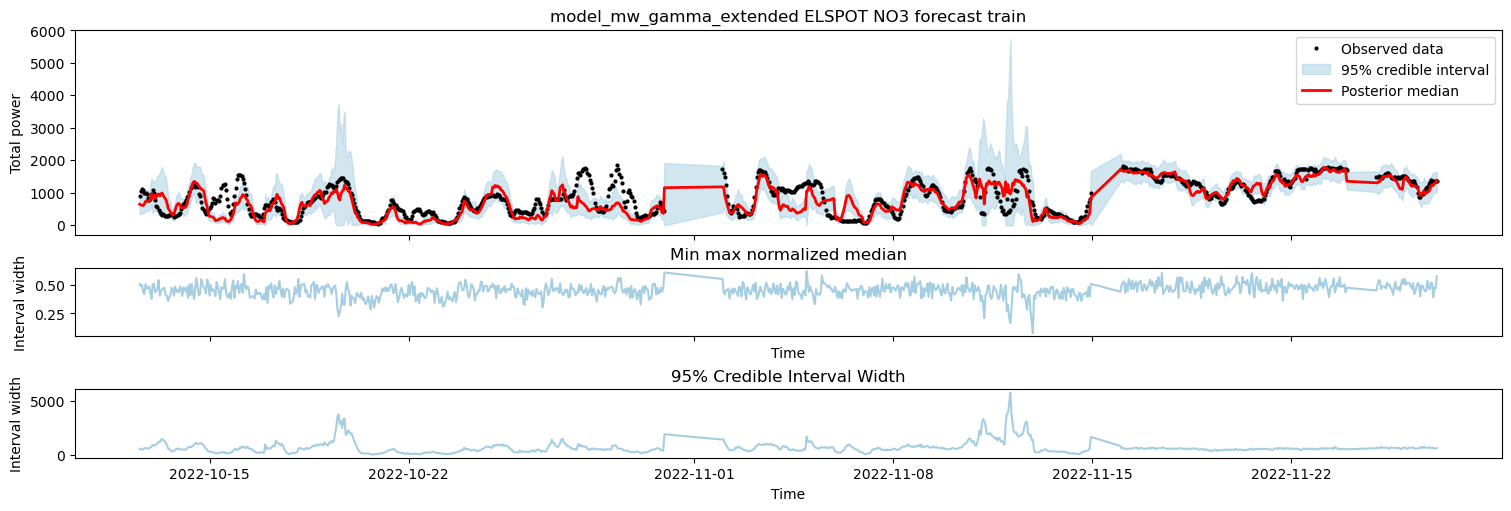

In [106]:
# Plot

fig, axes = plot_qr_hdi_prediction(
    Y_true=data["Y_train_gen"],
    conf_interval=hdis_train.T,  # hdi_list[0].T,
    medians=median_train,  # median_list[0],
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} train",
    timestamps=data["X_train_timestamps"],
)
plt.show()

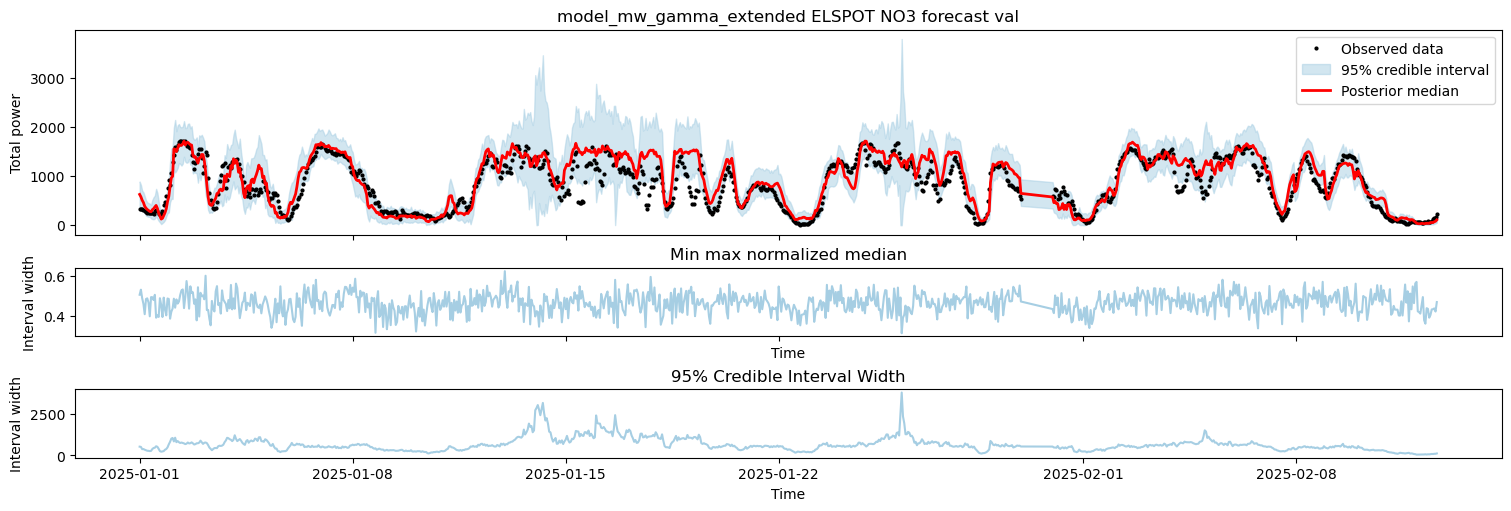

In [108]:
# Plot

fig, axes = plot_qr_hdi_prediction(
    Y_true=data["Y_test_gen"],
    conf_interval=hdi_list[0].T,
    medians=median_list[0],
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

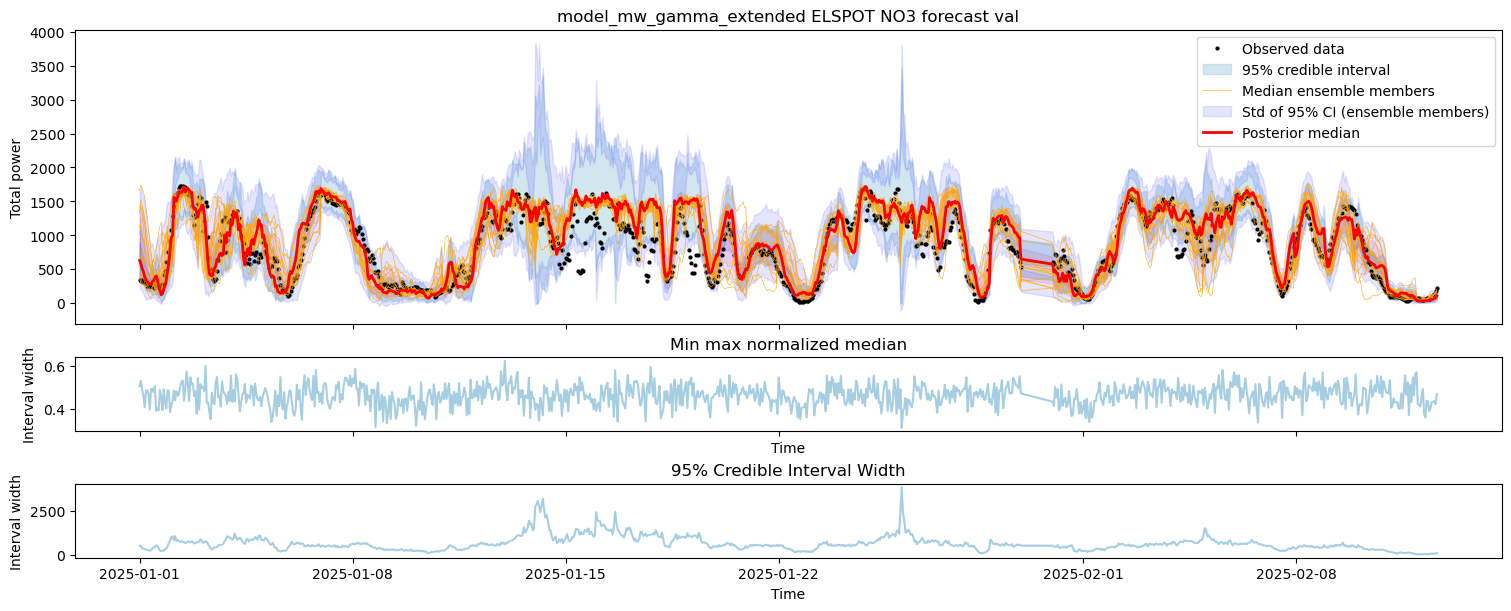

In [128]:
fig, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

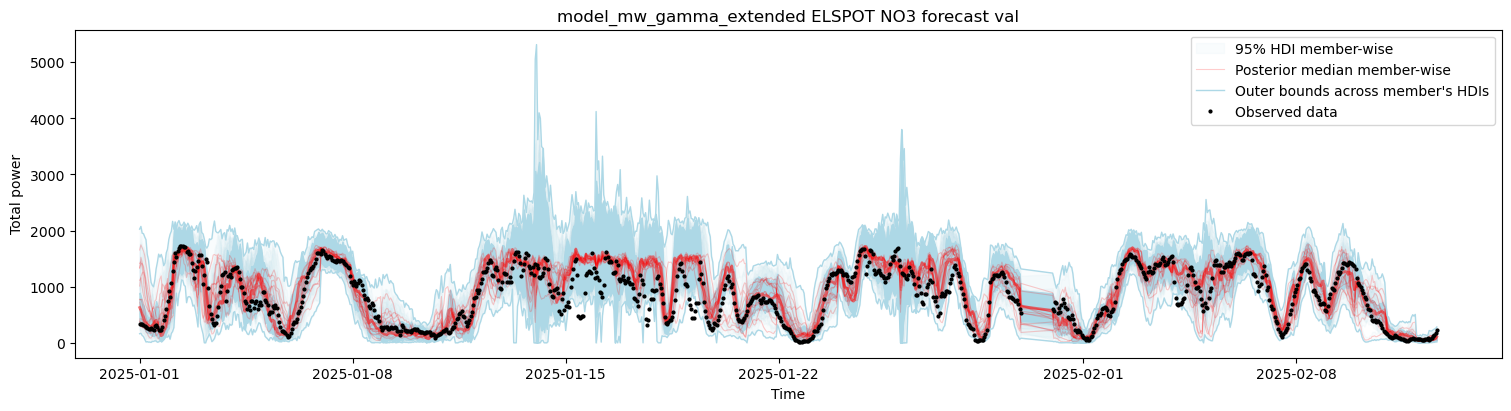

In [129]:
fig, axes = plot_qr_hdi_prediction_ensemble_outline(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

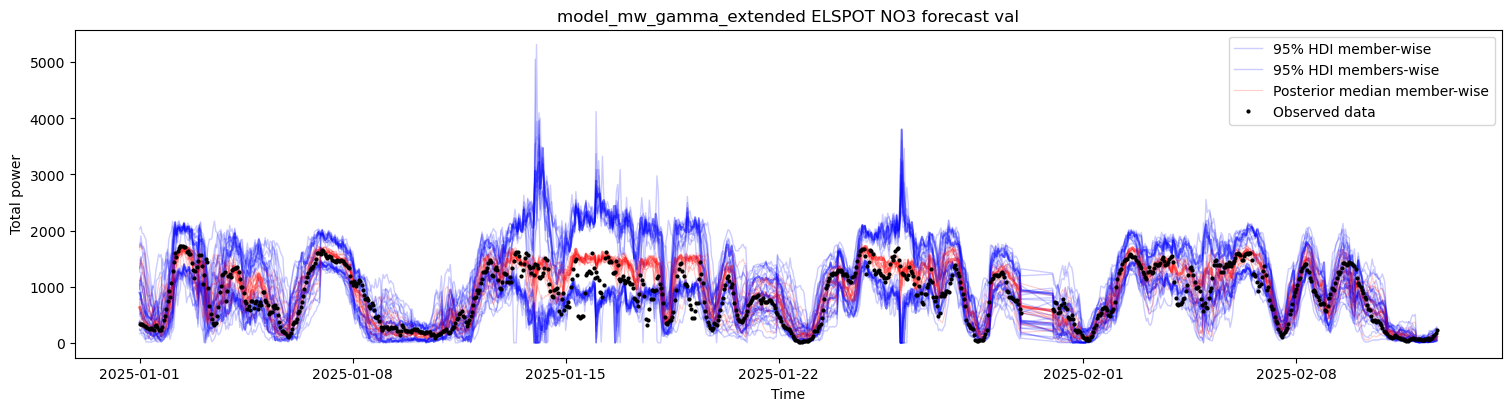

In [130]:
fig, axes = plot_qr_hdi_prediction_ensemble_std(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

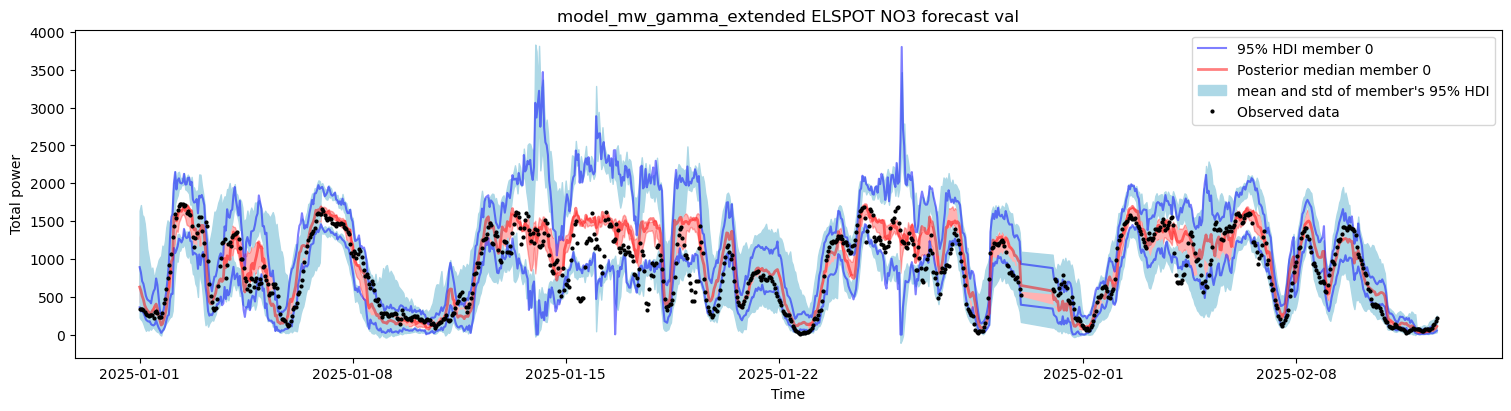

In [131]:
fig, axes = plot_qr_hdi_prediction_ensemble_std_bands(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

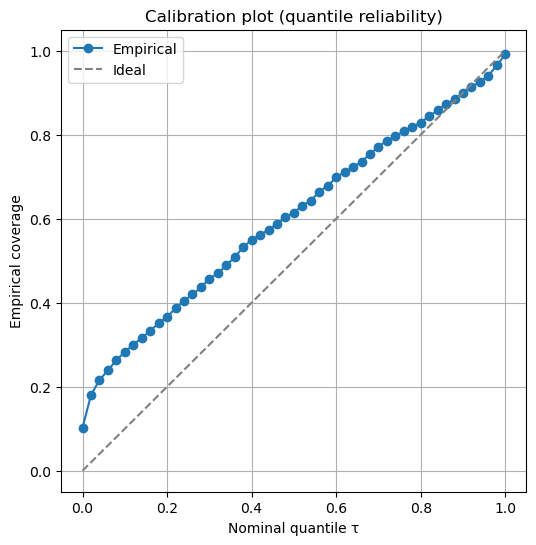

In [132]:
# y_pred: (S, N)

quantiles = torch.linspace(0, 1, 51)
emp_cov = plot_quantile_calibration(
    Y_pred_quantiles=(
        np.quantile(y_pred_list[0], quantiles, axis=0).T
        if model_cfg.backend == "numpyro"
        else y_pred
    ),
    Y_true=(
        data["Y_test_gen"] if model_cfg.params.target == "gen" else data["Y_test_cf"]
    ),
    quantiles=quantiles,
)

skew: -0.85013205


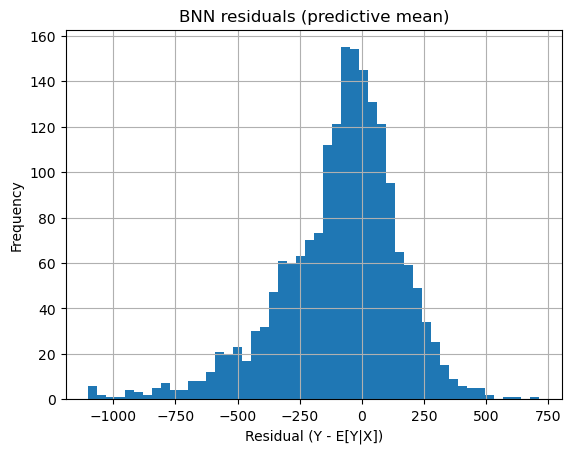

array([-291.99445, -245.79251, -168.52344, ...,  296.39935,  713.7081 ,
        590.85956], shape=(1895,), dtype=float32)

In [133]:
plot_residuals(
    median_list[0],
    data["Y_test_gen"],
)

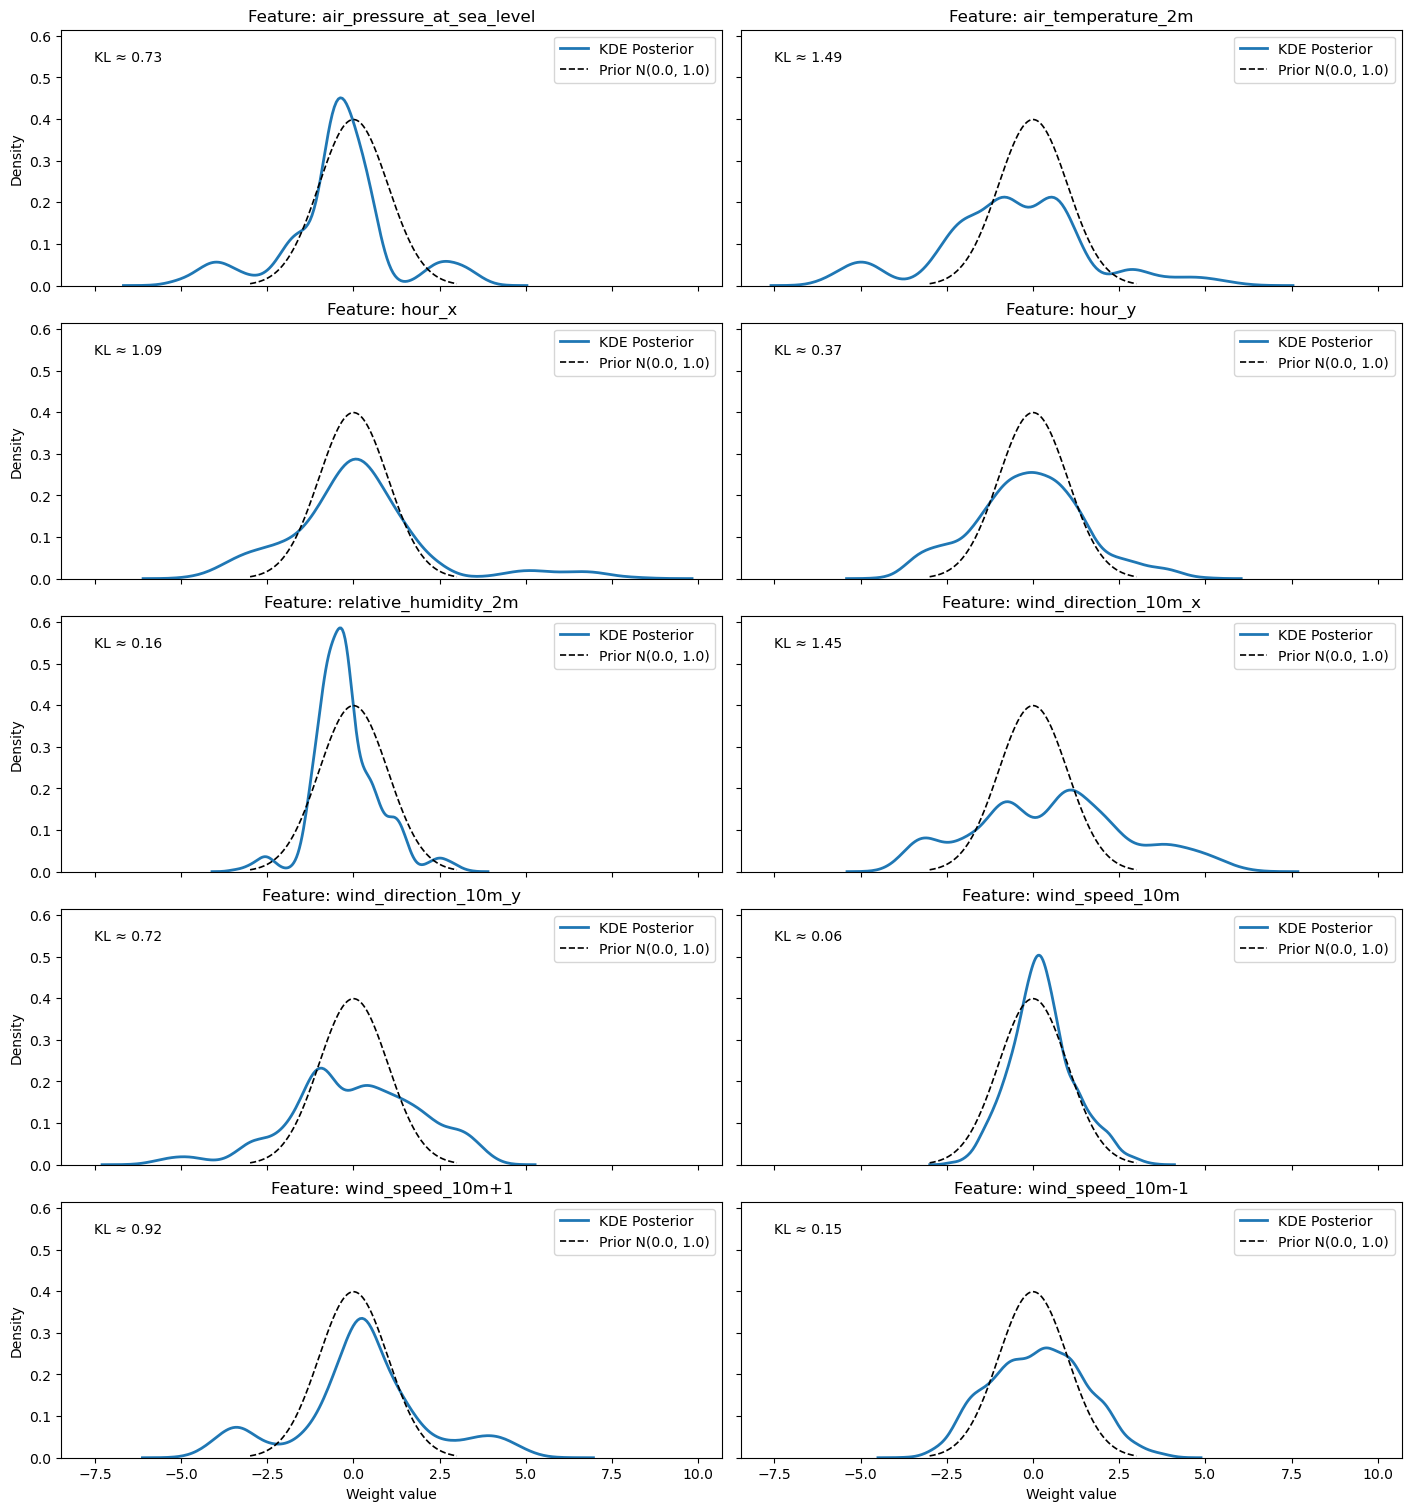

In [134]:
if model_cfg.backend == "numpyro":
    plot_first_layer_feature_posteriors(checkpoint["samples"], data)

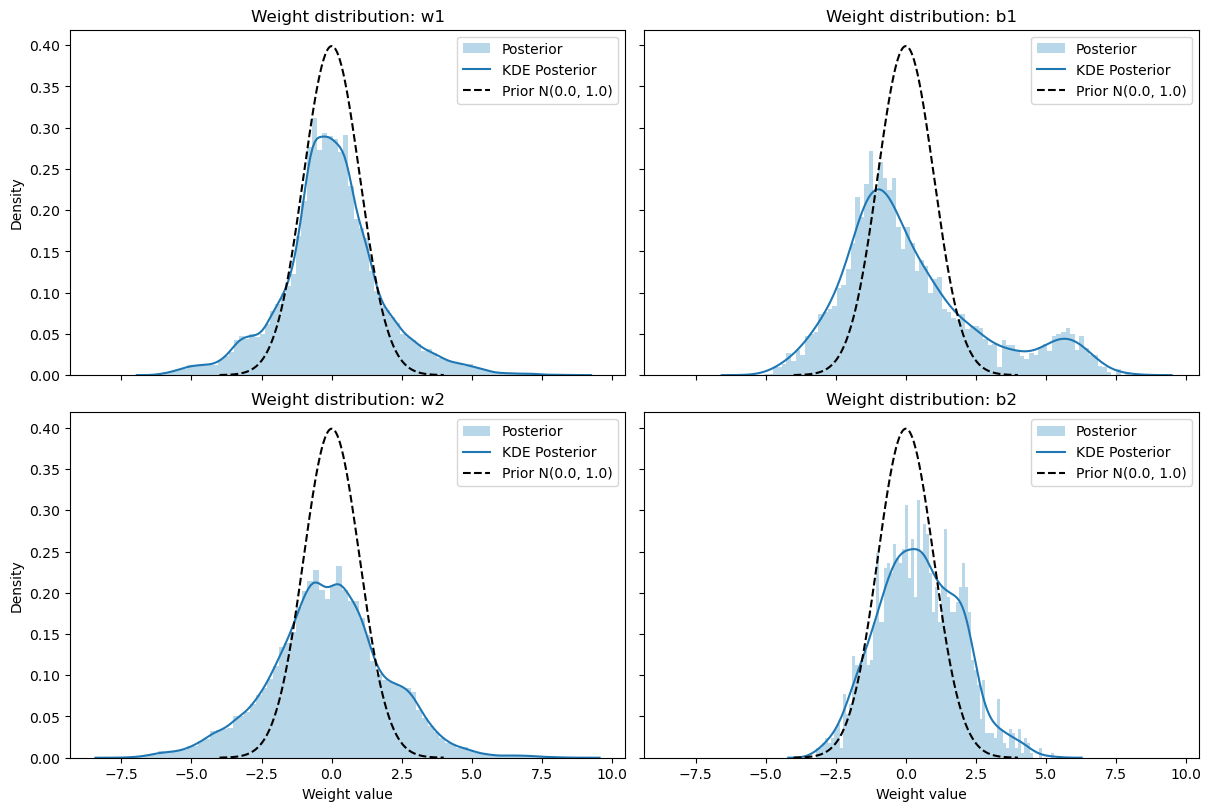

In [135]:
if model_cfg.backend == "numpyro":
    plot_bnn_weight_posteriors(checkpoint["samples"])

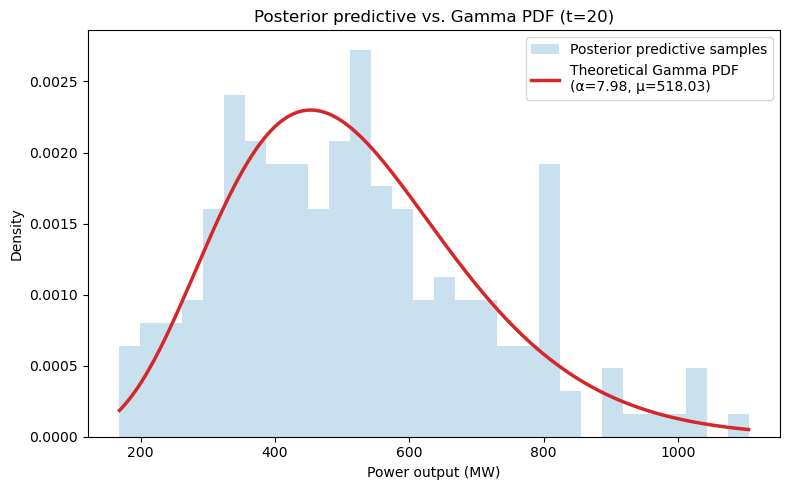

In [136]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_vs_likelihood(
        predictive=predictive,
        model_name=model_cfg.name,
        t=20,
    )

Y not none


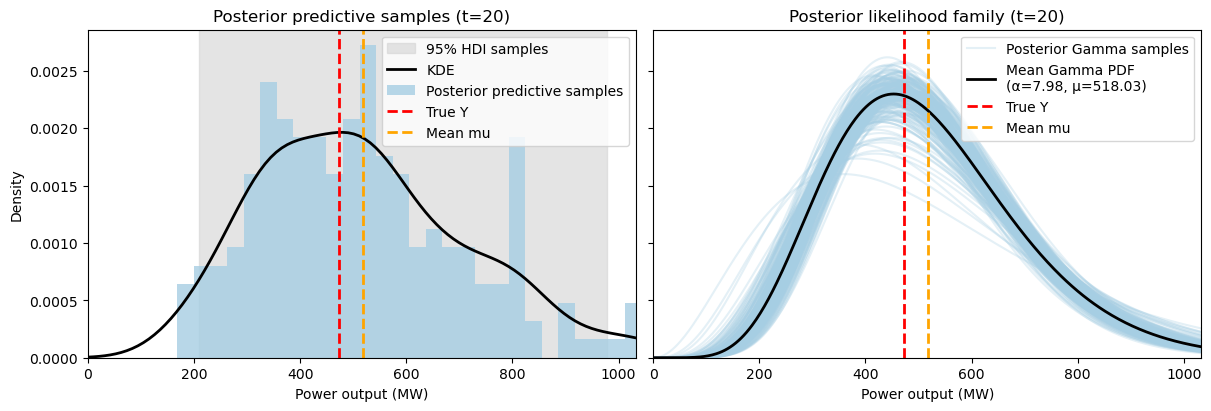

In [137]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_family(predictive, model_cfg, data, t=20, hdi=percentiles)

    # Epistemic uncertainty on the left: different outputs for the different model realizations
    # Aleatoric uncertainty on the right: different gamma distribution, each realization's variance informs about it's aleatoric uncertainty
    # TODO: does it make sense to take the mean of the parameters, so say something about its average aleatoric uncertainty?

In [138]:
if model_cfg.backend == "torch":
    plt.figure(figsize=(8, 5))
    plt.plot(checkpoint["losses"], label="Training Loss")
    plt.xlabel("Step")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

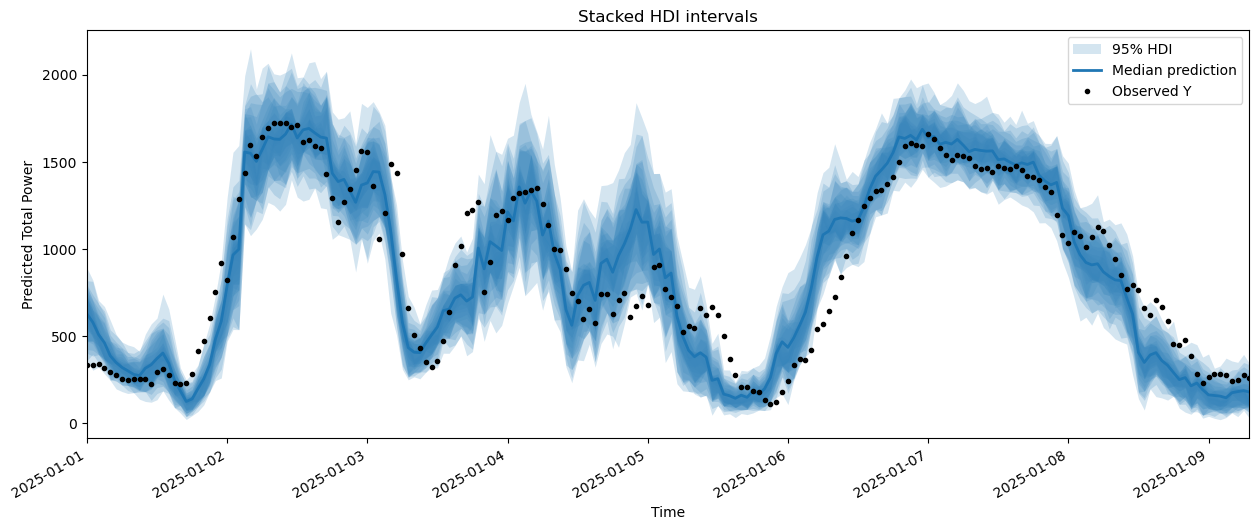

In [139]:
if model_cfg.backend == "numpyro":
    plot_stacked_hdi_intervals(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
        n_plot=200,
        timestamps=data["X_test_timestamps"],
    )

PIT mean: 0.3972 (should be ~1 if calibrated)


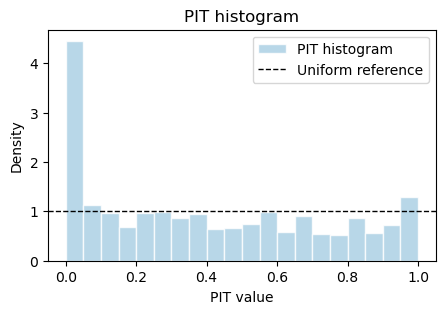

In [140]:
if model_cfg.backend == "numpyro":
    pits = plot_pit_histogram(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
    )

In [141]:
if model_cfg.backend == "torch" and len(data["X_train"].shape) == 4:
    evaluate_and_plot_qr_ensemble_medians(
        model=model,
        data=data,
        quantiles=quantiles,
        n_members=15,
        n_plot=1000,
    )

Compare learned weights for aggregation and max capacity of parks


In [142]:
import torch

print(
    "Max capacity wind parks: ",
    torch.softmax(torch.tensor(data["sites_meta"]), 0).reshape([-1]),
)
print("Learned weightings wind parks: ", samples["agg_logits"].mean(0))

Max capacity wind parks:  tensor([0.0141, 0.0335, 0.0143, 0.0805, 0.1022, 0.0433, 0.0100, 0.0371, 0.0127,
        0.0513, 0.0135, 0.0350, 0.0128, 0.0089, 0.0084, 0.0066, 0.0075, 0.0525,
        0.0217, 0.3691, 0.0394, 0.0074, 0.0073, 0.0108], dtype=torch.float64)
Learned weightings wind parks:  [0.01646274 0.01049633 0.01803901 0.13394958 0.08061519 0.01088206
 0.00623929 0.06966784 0.05736451 0.05747639 0.0025049  0.05864834
 0.00689914 0.01561102 0.01239422 0.01142795 0.06034186 0.04863355
 0.08207543 0.09006735 0.12041225 0.00527697 0.01020937 0.01430467]


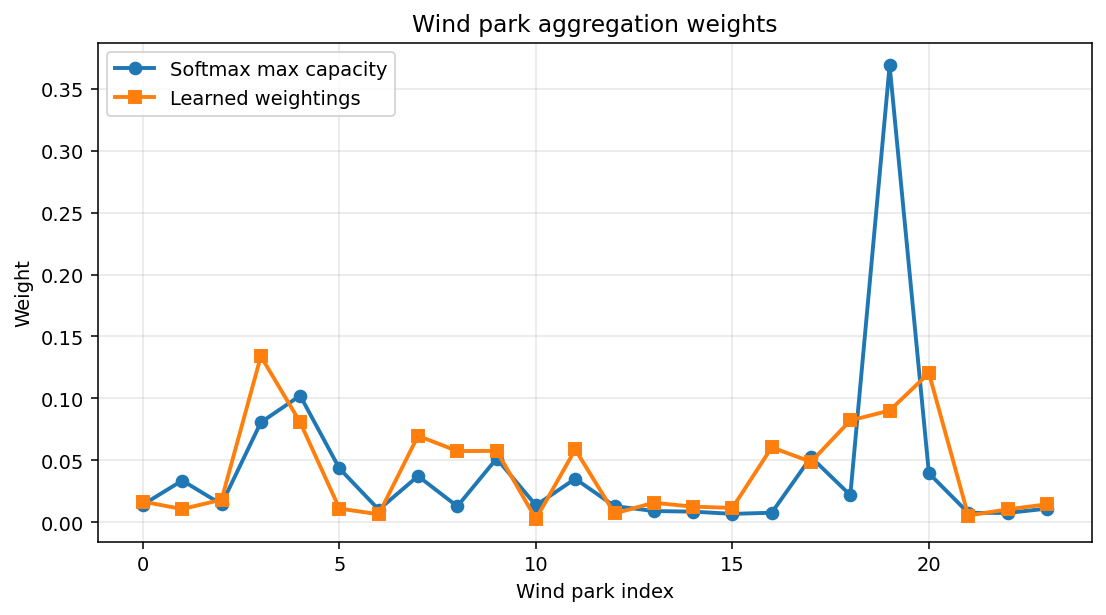

In [143]:
softmax_caps = torch.softmax(torch.tensor(data["sites_meta"]), 0).numpy()
learned_weights = samples["agg_logits"].mean(0)
x = np.arange(len(softmax_caps))

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=140)

ax.plot(
    x,
    softmax_caps,
    marker="o",
    lw=2,
    label="Softmax max capacity",
)

ax.plot(
    x,
    learned_weights,
    marker="s",
    lw=2,
    label="Learned weightings",
)

ax.set_xlabel("Wind park index")
ax.set_ylabel("Weight")
ax.set_title("Wind park aggregation weights")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()